# Logistic Regression (Binary Classification) - Stochastic Gradient Descent
Dataset: [Pima Indians Diabetes](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) from Kaggle.

Goal: predict if a patient has diabetes (1) or not (0).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

In [2]:
data = pd.read_csv("../data/diabetes.csv")
print(data.shape)
print(data.isnull().sum().sum())
data.head()

(768, 9)
0

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Outcome
0    500
1    268
Name: count, dtype: int64

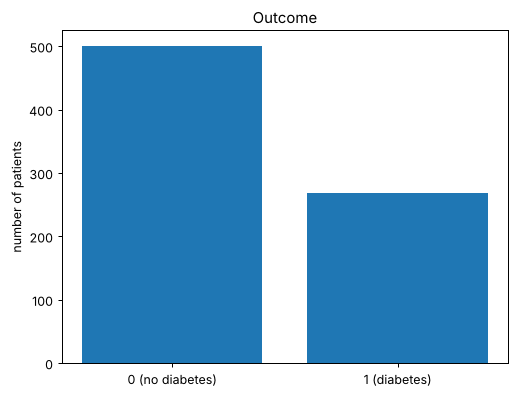

In [3]:
counts = data["Outcome"].value_counts()
print(counts)

plt.bar(["0 (no diabetes)", "1 (diabetes)"], [counts[0], counts[1]])
plt.ylabel("number of patients")
plt.title("Outcome")
plt.show()

In [4]:
# some columns have 0 where the value is missing (nobody has glucose = 0)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((data[cols] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

## Prepare the data

In [5]:
X_raw = data.drop("Outcome", axis=1).values.astype(float)
y = data["Outcome"].values

# split 80% train, 20% test
np.random.seed(42)
indices = np.random.permutation(len(y))
n_train = int(0.8 * len(y))
train_idx = indices[:n_train]
test_idx = indices[n_train:]

# replace the zeros with the median of the train data
# columns 1 to 5 = Glucose, BloodPressure, SkinThickness, Insulin, BMI
for col in range(1, 6):
    train_values = X_raw[train_idx, col]
    median = np.median(train_values[train_values != 0])
    X_raw[X_raw[:, col] == 0, col] = median

# scaling (mean and std from the train data only)
mean = X_raw[train_idx].mean(axis=0)
std = X_raw[train_idx].std(axis=0)
X_scaled = (X_raw - mean) / std

# add the bias column (ones)
X = np.ones((len(y), 9))
X[:, 1:] = X_scaled

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]
print(X_train.shape, X_test.shape)

(614, 9) (154, 9)

## Functions
`sigmoid` turns any number into a probability between 0 and 1. The loss is binary cross-entropy.

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict_proba(X, theta):
    return sigmoid(X.dot(theta))

def predict(X, theta):
    return (predict_proba(X, theta) >= 0.5).astype(int)

def compute_loss(X, y, theta):
    p = predict_proba(X, theta)
    p = np.clip(p, 1e-15, 1 - 1e-15)   # to avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def compute_gradient(X, y, theta):
    m = len(y)
    p = predict_proba(X, theta)
    return (1 / m) * X.T.dot(p - y)

## Metrics
Accuracy, Precision, Recall and F1 calculated from the confusion matrix.

In [7]:
def evaluate(y_true, y_pred):
    TP = np.sum((y_pred == 1) & (y_true == 1))
    TN = np.sum((y_pred == 0) & (y_true == 0))
    FP = np.sum((y_pred == 1) & (y_true == 0))
    FN = np.sum((y_pred == 0) & (y_true == 1))

    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * precision * recall / (precision + recall)
    return TP, TN, FP, FN, accuracy, precision, recall, f1

## Stochastic Gradient Descent (SGD)
We update theta after every single sample (one row at a time), in random order.

In [8]:
lr = 0.01
n_epochs = 50
m = len(y_train)

theta = np.zeros(9)
loss_history = []

for epoch in range(n_epochs):
    order = np.random.permutation(m)
    for i in order:
        xi = X_train[i:i+1]
        yi = y_train[i:i+1]
        gradient = compute_gradient(xi, yi, theta)
        theta = theta - lr * gradient
    loss_history.append(compute_loss(X_train, y_train, theta))

## Results (test data)

In [9]:
print("theta:", np.round(theta, 3))
print("train loss:", compute_loss(X_train, y_train, theta))
print("test loss:", compute_loss(X_test, y_test, theta))
print()

TP, TN, FP, FN, accuracy, precision, recall, f1 = evaluate(y_test, predict(X_test, theta))
print("TP:", TP, " TN:", TN, " FP:", FP, " FN:", FN)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))

theta: [-0.933  0.444  1.171 -0.108 -0.029 -0.173  0.62   0.297  0.17 ]
train loss: 0.4629288125175657
test loss: 0.47518410035298486

TP: 30  TN: 86  FP: 10  FN: 28
Accuracy: 0.7532
Precision: 0.75
Recall: 0.5172
F1: 0.6122

In [10]:
# accuracy on the train data, to check overfitting
train_acc = evaluate(y_train, predict(X_train, theta))[4]
print("train accuracy:", round(train_acc, 4))
print("test accuracy:", round(accuracy, 4))

train accuracy: 0.7883
test accuracy: 0.7532

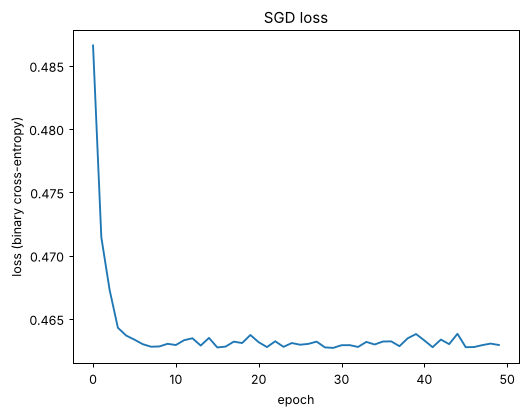

In [11]:
plt.plot(loss_history)
plt.xlabel("epoch")
plt.ylabel("loss (binary cross-entropy)")
plt.title("SGD loss")
plt.show()

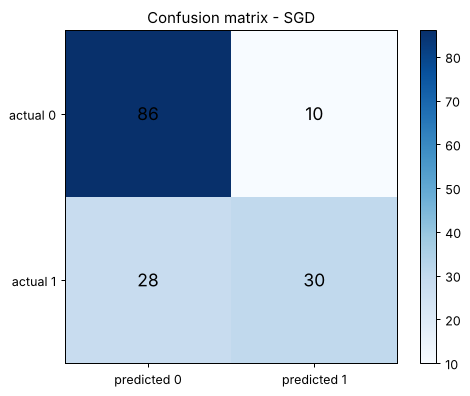

In [12]:
cm = np.array([[TN, FP], [FN, TP]])

plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1], ["predicted 0", "predicted 1"])
plt.yticks([0, 1], ["actual 0", "actual 1"])
plt.title("Confusion matrix - SGD")
plt.colorbar()
plt.show()

## Conclusion
SGD makes many cheap updates (one per sample), so it learns fast but the loss is a bit noisy.